Setups and Imports

In [1]:
pip install nlp

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------ ------------------------

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import random

In [3]:
def show_history(h):
    epochs_trained = len(h.history['loss'])
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    plt.plot(range(epochs_trained), h.history['accuracy'], label='Training')
    plt.plot(range(epochs_trained), h.history['val_accuracy'], label='Validation')
    plt.ylim([0., 1.])
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(range(epochs_trained), h.history['loss'], label='Training')
    plt.plot(range(epochs_trained), h.history['val_loss'], label='Validation')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

def show_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    plt.figure(figsize=(8, 8))
    plt.matshow(cm, cmap=plt.cm.RdYlGn)
    plt.colorbar()
    plt.xticks(range(len(classes)), classes, rotation=45)
    plt.yticks(range(len(classes)), classes)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## Importing Dataset

In [7]:
dataset = pd.read_csv('DATA_2.csv', encoding='ISO-8859-1')
dataset.head()

,Review,Sentiment
0,1:41 - 1:49 \n\nEPIC piece of music!! Shame it...,Negative
1,Boring yaarðð,Negative
2,We miss you Iron Manð¢,Negative
3,Waste of time,Negative
4,"It's already 2025, but Idk how many times I've...",Negative


In [8]:
# Check for nulls in critical columns
dataset[['Review', 'Sentiment']].isnull().sum()

Review       2
Sentiment    0
dtype: int64

In [9]:
# Split the dataset: 70% train, 15% validation, 15% test
train_data, temp_data = train_test_split(dataset, test_size=0.3, random_state=42)
val_data, test_data = train_test_split(temp_data, test_size=0.5, random_state=42)

# Confirm sizes
print(f"Train size: {len(train_data)}")
print(f"Validation size: {len(val_data)}")
print(f"Test size: {len(test_data)}")

Train size: 9341
Validation size: 2002
Test size: 2002


In [10]:
# Data extraction function
def get_tweet(data):
    # Drop rows where 'Review' or 'Sentiment' is NaN
    data = data.dropna(subset=['Review', 'Sentiment'])
    
    # Convert 'Review' to string and extract lists
    tweets = data['Review'].astype(str).tolist()
    labels = data['Sentiment'].tolist()
    
    return tweets, labels

In [11]:
# Example usage
train_tweets, train_labels = get_tweet(train_data)
val_tweets, val_labels = get_tweet(val_data)
test_tweets, test_labels = get_tweet(test_data)

# Preview some examples
for tweet, label in zip(train_tweets[:5], train_labels[:5]):
    print(f"{label}: {tweet}")

Positive: Back when Marvel was at the top of the world ð¢
Neutral: âPart of the journey is the endâ. Tony was speaking to the audience ð¢
Positive: It is not flop
Negative: &#8220;@BreadTruckkBri: These hoes gon come &amp;&amp; go, i feel it.&#8221;
Positive: I watched it at movie theatre, this movie deserve each penny. Cinematic and camera effects are superb


Tokenizer

In [13]:
maxlen = 50
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=10000, oov_token='<UNK>')
train_tweets, train_labels = get_tweet(train_data)
tokenizer.fit_on_texts(train_tweets)


In [14]:
print(train_tweets[4])

I watched it at movie theatre, this movie deserve each penny. Cinematic and camera effects are superb


In [15]:
def get_sequences(tokenizer, tweets):
    sequences = tokenizer.texts_to_sequences(tweets)
    padded = tf.keras.preprocessing.sequence.pad_sequences(
        sequences, maxlen=maxlen, padding='post', truncating='post'
    )
    return padded

In [16]:
classes = sorted(set(train_labels))  # Ensure consistent ordering
class_to_index = {c: i for i, c in enumerate(classes)}
index_to_class = {i: c for i, c in enumerate(classes)}
names_to_ids = lambda labels: np.array([class_to_index[x] for x in labels])

In [17]:
tokenizer.texts_to_sequences([train_tweets[4]])


[[3,
  106,
  11,
  50,
  12,
  818,
  6,
  12,
  1072,
  591,
  7762,
  701,
  4,
  1250,
  843,
  30,
  1441]]

In [18]:
train_tweets[4]


'I watched it at movie theatre, this movie deserve each penny. Cinematic and camera effects are superb'

Padding and Truncating Sequences

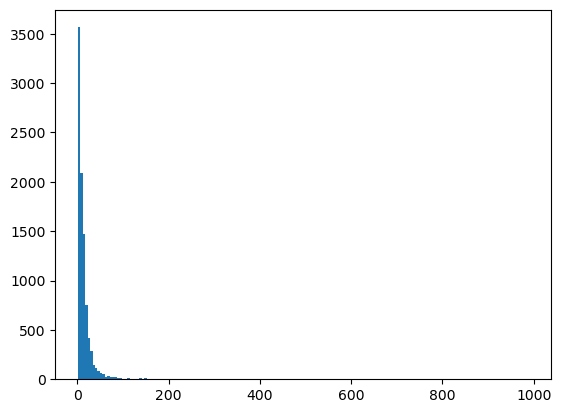

In [19]:
lengths = [len(t.split(' ')) for t in train_tweets]
plt.hist(lengths, bins=len(set(lengths)))
plt.show()


Preparing the labels

In [20]:
train_tweets, labels = get_tweet(train_data)
classes = set(labels)
print(classes)

{'Negative', 'Neutral', 'Positive'}


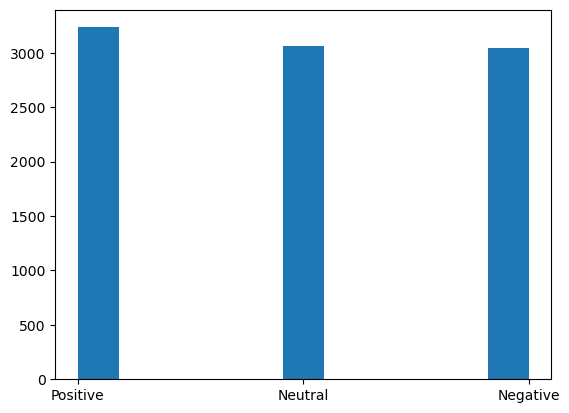

In [21]:
plt.hist(labels, bins=11)
plt.show()

In [22]:
class_to_index = dict((c,i) for i,c in enumerate(classes))
index_to_class = dict((v,k) for k,v in class_to_index.items())

In [23]:
class_to_index

{'Negative': 0, 'Neutral': 1, 'Positive': 2}

In [24]:
index_to_class

{0: 'Negative', 1: 'Neutral', 2: 'Positive'}

In [25]:
names_to_ids = lambda labels:np.array([class_to_index.get(x) for x in labels])

In [26]:
train_labels = names_to_ids(labels)
print(train_labels[6])

2


Creating the Model

In [27]:
def process_data(tweets, labels):
    # Filter out empty or invalid tweets and keep labels aligned
    valid_pairs = [(t, l) for t, l in zip(tweets, labels) if t.strip()]
    if not valid_pairs:
        raise ValueError("No valid data after filtering")
    valid_tweets, valid_labels = zip(*valid_pairs)
    seq = get_sequences(tokenizer, valid_tweets)
    labels_array = names_to_ids(valid_labels)
    return seq, labels_array

In [28]:
train_seq, train_labels = process_data(train_tweets, train_labels)
val_tweets, val_labels = get_tweet(val_data)
val_seq, val_labels = process_data(val_tweets, val_labels)
test_tweets, test_labels = get_tweet(test_data)
test_seq, test_labels = process_data(test_tweets, test_labels)

In [29]:
print(f"Train samples: {len(train_seq)}, Train labels: {len(train_labels)}")
print(f"Val samples: {len(val_seq)}, Val labels: {len(val_labels)}")
print(f"Test samples: {len(test_seq)}, Test labels: {len(test_labels)}")

Train samples: 9339, Train labels: 9339
Val samples: 2002, Val labels: 2002
Test samples: 2002, Test labels: 2002


In [30]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Embedding(10000, 32, input_length=maxlen),

    # First BiLSTM with dropout
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(32, return_sequences=True, dropout=0.3, recurrent_dropout=0.3)
    ),

    # Second BiLSTM with dropout
    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(32, dropout=0.3, recurrent_dropout=0.3)
    ),

    # Dense + Dropout + L2 Regularization
    tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dropout(0.4),  # Slightly higher dropout

    # Output layer
    tf.keras.layers.Dense(3, activation='softmax')
])

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=optimizer,
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 50, 32)            320000    
                                                                 
 bidirectional (Bidirectiona  (None, 50, 64)           16640     
 l)                                                              
                                                                 
 bidirectional_1 (Bidirectio  (None, 64)               24832     
 nal)                                                            
                                                                 
 dense (Dense)               (None, 64)                4160      
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 3)                 1

Training the Model

In [31]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001)
]

In [ ]:
def names_to_ids(labels):
    """Converts a list of labels to a NumPy array of label IDs.
    Handles unknown labels by assigning a default label (e.g., 0).
    """
    # Use a default value (0) if label not found in class_to_index
    return np.array([class_to_index.get(x, 0) for x in labels])

# Ensure train_labels is a list before processing
train_tweets, labels = get_tweet(train_data)
train_labels = names_to_ids(labels) # Process labels before train_seq
train_seq, _ = process_data(train_tweets, train_labels)  # _ to ignore the second output

# Convert train_labels and val_labels to int64 after processing
train_labels = np.array(train_labels, dtype=np.int64)
val_labels = np.array(val_labels, dtype=np.int64)

h = model.fit(
    train_seq, train_labels,
    validation_data=(val_seq, val_labels),
    epochs=20,
    batch_size=64,  
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
136/146 [==========================>...] - ETA: 10s - loss: 1.2809 - accuracy: 0.4995  

Evaluating the Model

In [ ]:
show_history(h)

In [ ]:
test_loss, test_acc = model.evaluate(test_seq, test_labels)
print(f"Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")

In [ ]:
i = random.randint(0, len(test_labels)-1)
print('Sentence: ',test_tweets[i]) # Changed test_tweet to test_tweets
print('Emotion: ',index_to_class[test_labels[i]])
p = model.predict(np.expand_dims(test_seq[i], axis=0))[0]
pred_class = index_to_class[np.argmax(p).astype('uint8')]
print('Predicted Emotion: ',pred_class)

In [ ]:
preds = model.predict(test_seq)
classes_x = np.argmax(preds, axis=1)

In [ ]:
print(set(test_labels))
print(set(classes_x))
print(len(list(classes)))

In [ ]:
show_confusion_matrix(test_labels, classes_x, list(classes))

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:\n")
print(classification_report(test_labels, classes_x, target_names=list(classes)))